# Laboratório — neurônio artificial e funções de ativação
**Aprendizado de Máquina (PEPAPRM) · IFSP Presidente Epitácio**

Demonstração guiada do laboratório. Aqui o neurônio é construído do zero em NumPy, depois usado para comparar as funções de ativação, montar portas lógicas, resolver o XOR com duas camadas e medir o gradiente que desaparece. Nenhum arquivo de dados é necessário.

In [1]:
import itertools
import warnings

import matplotlib
matplotlib.use("Agg")                      # no notebook as figuras aparecem na tela
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 110)
AZUL, VERMELHO, CINZA = "#1F3864", "#C0392B", "#7F8C8D"


def secao(n, titulo):
    print()
    print("=" * 70)
    print(f"PASSO {n} - {titulo}")
    print("=" * 70)

## Passo 1 — o neurônio em NumPy
Uma função para cada ativação e uma classe com dois métodos: `z` (soma ponderada mais viés) e `saida` (ativação aplicada a `z`). O mesmo código aceita um vetor de entrada ou um lote inteiro.

In [2]:
secao(1, "O NEURONIO EM NUMPY, CONFERIDO COM O EXEMPLO FEITO A MAO")


def degrau(z):
    return np.where(np.asarray(z, dtype=float) >= 0, 1.0, 0.0)


def identidade(z):
    return np.asarray(z, dtype=float)


def sigmoide(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=float)))


def tanh(z):
    return np.tanh(np.asarray(z, dtype=float))


def relu(z):
    return np.maximum(0.0, np.asarray(z, dtype=float))


def leaky_relu(z, alpha=0.01):
    z = np.asarray(z, dtype=float)
    return np.where(z > 0, z, alpha * z)


ATIVACOES = {"degrau": degrau, "identidade": identidade, "sigmoide": sigmoide,
             "tanh": tanh, "relu": relu, "leaky_relu": leaky_relu}


class Neuronio:
    def __init__(self, w, b, ativacao="sigmoide"):
        self.w = np.asarray(w, dtype=float)
        self.b = float(b)
        self.ativacao = ativacao

    def z(self, X):
        """Soma ponderada + vies. X pode ser um vetor (d,) ou um lote (n, d)."""
        return np.asarray(X, dtype=float) @ self.w + self.b

    def saida(self, X):
        return ATIVACOES[self.ativacao](self.z(X))


# exemplo feito a mao na apostila de conceitos: z = -0,3
x = np.array([2.0, -1.0, 3.0])
w = [0.5, 1.0, -0.2]
b = 0.3
print(f"z = {Neuronio(w, b).z(x):+.3f}")
for nome in ATIVACOES:
    print(f"  {nome:<11} y = {Neuronio(w, b, nome).saida(x):+.3f}")


PASSO 1 - O NEURONIO EM NUMPY, CONFERIDO COM O EXEMPLO FEITO A MAO
z = -0.300
  degrau      y = +0.000
  identidade  y = -0.300
  sigmoide    y = +0.426
  tanh        y = -0.291
  relu        y = +0.000
  leaky_relu  y = -0.003


## Passo 2 — o mesmo neurônio, cinco ativações
Mesmos pesos, mesmo viés, mesmas entradas: só a ativação muda. Os mapas mostram a saída em cada ponto do plano. A linha de decisão `z = 0` é idêntica nos cinco; o que muda é o que acontece ao redor dela.


PASSO 2 - MAPAS DE SAIDA DO MESMO NEURONIO COM CINCO ATIVACOES
                z  degrau  sigmoide   tanh  relu  leaky_relu
ponto                                                       
A (2, 2)      3.0     1.0     0.953  0.995   3.0        3.00
B (0,8; 0,6)  0.4     1.0     0.599  0.380   0.4        0.40
C (-1; -1)   -3.0     0.0     0.047 -0.995   0.0       -0.03


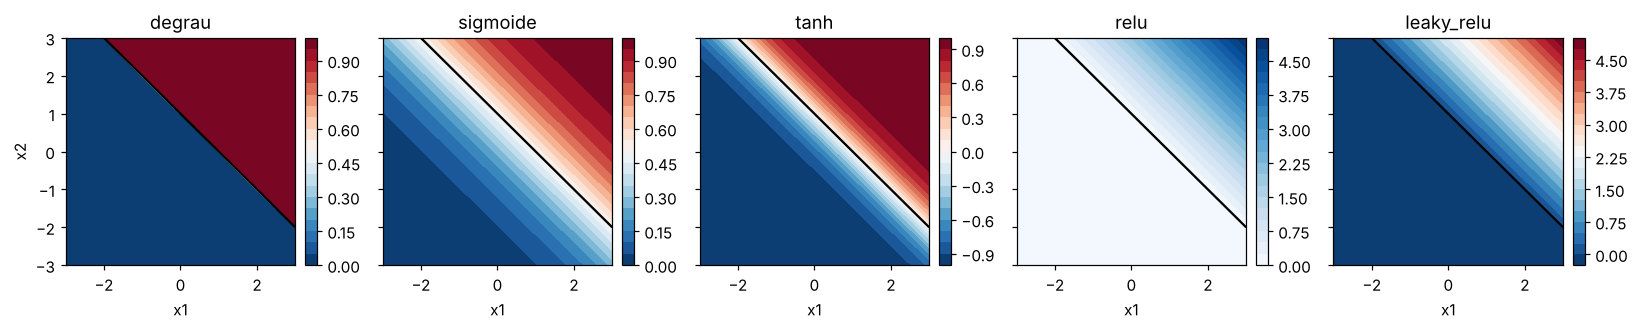

In [3]:
secao(2, "MAPAS DE SAIDA DO MESMO NEURONIO COM CINCO ATIVACOES")
w2, b2 = [1.0, 1.0], -1.0
g = np.linspace(-3, 3, 241)
G1, G2 = np.meshgrid(g, g)
grade = np.c_[G1.ravel(), G2.ravel()]

fig, eixos = plt.subplots(1, 5, figsize=(15, 3.1), sharey=True)
for ax, nome in zip(eixos, ["degrau", "sigmoide", "tanh", "relu", "leaky_relu"]):
    S = Neuronio(w2, b2, nome).saida(grade).reshape(G1.shape)
    cs = ax.contourf(G1, G2, S, levels=20, cmap="RdBu_r" if nome != "relu" else "Blues")
    ax.contour(G1, G2, G1 + G2 + b2, levels=[0], colors="k", linewidths=1.5)
    ax.set_title(nome)
    ax.set_xlabel("x1")
    fig.colorbar(cs, ax=ax, fraction=0.046, pad=0.04)
eixos[0].set_ylabel("x2")
plt.tight_layout()
plt.savefig("mapas_ativacao.png", dpi=150, bbox_inches="tight")
plt.show()

pontos = {"A (2, 2)": [2, 2], "B (0,8; 0,6)": [0.8, 0.6], "C (-1; -1)": [-1, -1]}
linhas = []
for nome_p, p in pontos.items():
    linha = {"ponto": nome_p, "z": Neuronio(w2, b2).z(p)}
    for nome in ["degrau", "sigmoide", "tanh", "relu", "leaky_relu"]:
        linha[nome] = float(Neuronio(w2, b2, nome).saida(p))
    linhas.append(linha)
print(pd.DataFrame(linhas).set_index("ponto").round(3).to_string())

## Passo 3 — portas lógicas por busca em grade
Quantas combinações de `(w1, w2, b)` de uma grade reproduzem cada porta? Para AND existem várias; para XOR, nenhuma.

In [4]:
secao(3, "QUANTAS COMBINACOES DE PESOS REPRODUZEM CADA PORTA")
entradas = list(itertools.product([0, 1], repeat=2))
alvos = {"AND": [0, 0, 0, 1], "XOR": [0, 1, 1, 0]}
grade_pesos = np.arange(-1.5, 1.51, 0.5)
contagem = {k: 0 for k in alvos}
exemplo = {}
for a, c, d in itertools.product(grade_pesos, grade_pesos, grade_pesos):
    s = [int(Neuronio([a, c], d, "degrau").saida(e)) for e in entradas]
    for k, v in alvos.items():
        if s == v:
            contagem[k] += 1
            exemplo.setdefault(k, (float(a), float(c), float(d)))
print(f"combinacoes testadas: {len(grade_pesos) ** 3}")
for k in alvos:
    print(f"  {k:<4} solucoes: {contagem[k]:>3}   primeira encontrada: {exemplo.get(k)}")


PASSO 3 - QUANTAS COMBINACOES DE PESOS REPRODUZEM CADA PORTA
combinacoes testadas: 343
  AND  solucoes:   4   primeira encontrada: (0.5, 0.5, -1.0)
  XOR  solucoes:   0   primeira encontrada: None


## Passo 4 — o gradiente através da profundidade
Uma cadeia de `L` camadas com um neurônio cada. Pela regra da cadeia, `d saída / d entrada` é o produto de `w · φ'(z)` de todas as camadas.


PASSO 4 - GRADIENTE ATRAVES DE L CAMADAS (UM NEURONIO POR CAMADA)
w = 2:
    sigmoide     tanh     relu
L                             
1      0.393     0.84        2
5    0.00233  0.00168       32
10  2.95e-06 2.14e-07 1.02e+03
20  4.75e-12 3.48e-15 1.05e+06
30  7.64e-18 5.65e-23 1.07e+09


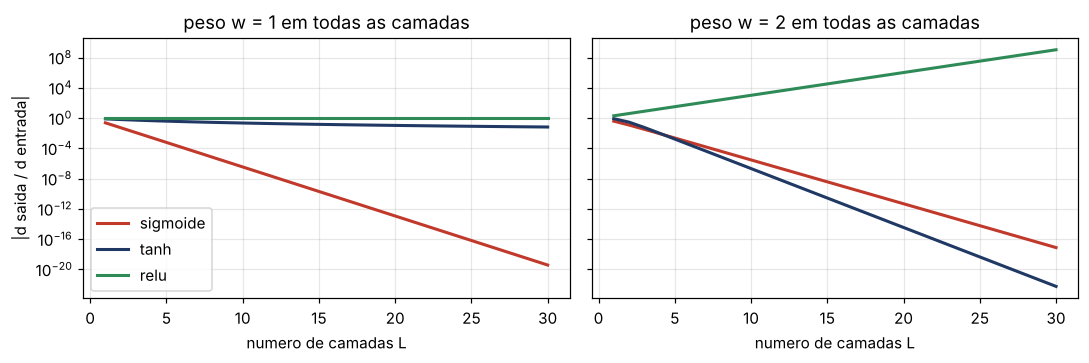

In [5]:
secao(4, "GRADIENTE ATRAVES DE L CAMADAS (UM NEURONIO POR CAMADA)")
DERIV = {
    "sigmoide": lambda z: sigmoide(z) * (1 - sigmoide(z)),
    "tanh": lambda z: 1 - np.tanh(z) ** 2,
    "relu": lambda z: np.where(z > 0, 1.0, 0.0),
}


def cadeia(x0, w, L, ativacao):
    a, grad = x0, 1.0
    for _ in range(L):
        z = w * a
        grad *= w * DERIV[ativacao](z)
        a = ATIVACOES[ativacao](z)
    return grad


fig, eixos = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
Ls = np.arange(1, 31)
for ax, w in zip(eixos, [1.0, 2.0]):
    for nome, cor in zip(["sigmoide", "tanh", "relu"], [VERMELHO, AZUL, "#2E8B57"]):
        ax.semilogy(Ls, [abs(cadeia(0.5, w, L, nome)) for L in Ls], label=nome, color=cor, lw=2)
    ax.set_title(f"peso w = {w:g} em todas as camadas")
    ax.set_xlabel("numero de camadas L")
    ax.grid(alpha=0.3)
eixos[0].set_ylabel("|d saida / d entrada|")
eixos[0].legend()
plt.tight_layout()
plt.savefig("gradiente_profundidade.png", dpi=150, bbox_inches="tight")
plt.show()

linhas = []
for L in [1, 5, 10, 20, 30]:
    linhas.append({"L": L, **{n: abs(cadeia(0.5, 2.0, L, n)) for n in ["sigmoide", "tanh", "relu"]}})
print("w = 2:")
print(pd.DataFrame(linhas).set_index("L").to_string(float_format=lambda v: f"{v:.3g}"))

## Passo 5 — duas camadas resolvem o que um neurônio não resolve
O XNOR (vale 1 quando as entradas são iguais) não é separável por uma reta. Com dois neurônios ocultos (AND e NOR) e um de saída (OR), cada neurônio ainda é linear, mas a camada oculta leva os pontos a um espaço em que uma reta separa as classes.


PASSO 5 - XNOR COM DUAS CAMADAS E O COLAPSO SEM NAO LINEARIDADE
entradas       : [[0, 0], [0, 1], [1, 0], [1, 1]]
oculta (AND,NOR): [[0, 1], [0, 0], [0, 0], [1, 0]]
saida XNOR      : [1, 0, 0, 1] (esperado [1, 0, 0, 1])

com identidade nas duas camadas: [-1.5, -1.5, -1.5, -1.5]
W' = W2 @ W1 = [[0.0, 0.0]]   b' = [-1.5]


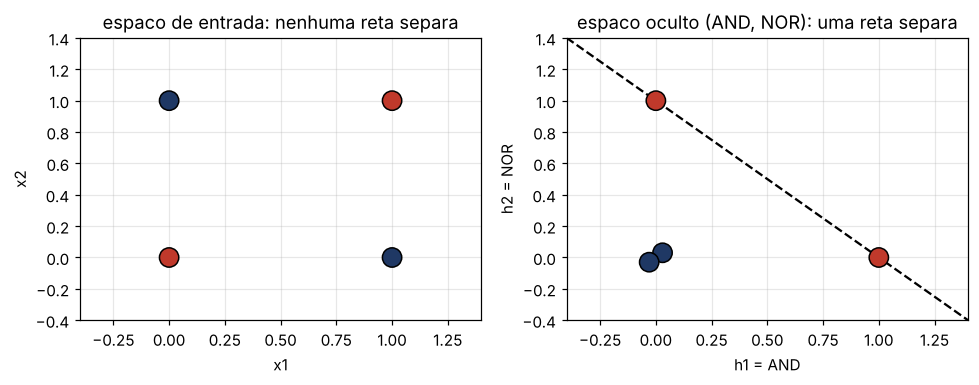

In [6]:
secao(5, "XNOR COM DUAS CAMADAS E O COLAPSO SEM NAO LINEARIDADE")


def camada(X, W, b, ativacao):
    return ATIVACOES[ativacao](np.asarray(X, dtype=float) @ W.T + b)


E = np.array(entradas, dtype=float)
W1 = np.array([[1.0, 1.0], [-1.0, -1.0]])       # oculta: AND e NOR
b1 = np.array([-1.5, 0.5])
W2 = np.array([[1.0, 1.0]])                      # saida: OR das duas
b2 = np.array([-0.5])

H = camada(E, W1, b1, "degrau")
Y = camada(H, W2, b2, "degrau")
print("entradas       :", E.astype(int).tolist())
print("oculta (AND,NOR):", H.astype(int).tolist())
print("saida XNOR      :", Y.ravel().astype(int).tolist(), "(esperado [1, 0, 0, 1])")

Yi = camada(camada(E, W1, b1, "identidade"), W2, b2, "identidade")
print("\ncom identidade nas duas camadas:", Yi.ravel().tolist())
print("W' = W2 @ W1 =", (W2 @ W1).tolist(), "  b' =", (W2 @ b1 + b2).tolist())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.6))
alvo = Y.ravel().astype(int)
cores = [VERMELHO if t == 1 else AZUL for t in alvo]
ax1.scatter(E[:, 0], E[:, 1], c=cores, s=160, edgecolor="k", zorder=3)
ax1.set(title="espaco de entrada: nenhuma reta separa", xlabel="x1", ylabel="x2", xlim=(-0.4, 1.4), ylim=(-0.4, 1.4))
ax2.scatter(H[:, 0] + [0, 0.03, -0.03, 0], H[:, 1] + [0, 0.03, -0.03, 0], c=cores, s=160, edgecolor="k", zorder=3)
ax2.plot([-0.4, 1.4], [1.4, -0.4], "k--", lw=1.5)
ax2.set(title="espaco oculto (AND, NOR): uma reta separa", xlabel="h1 = AND", ylabel="h2 = NOR", xlim=(-0.4, 1.4), ylim=(-0.4, 1.4))
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("xnor_duas_camadas.png", dpi=150, bbox_inches="tight")
plt.show()

## Passo 6 — softmax e temperatura
A softmax recebe o vetor de pontuações da camada de saída. Dividir as pontuações por uma temperatura `T` controla o quanto a distribuição é concentrada.

In [7]:
secao(6, "SOFTMAX ESTAVEL E TEMPERATURA")


def softmax(z, T=1.0):
    z = np.asarray(z, dtype=float) / T
    e = np.exp(z - z.max())            # subtrair o maximo evita overflow
    return e / e.sum()


z0 = [2.0, 1.0, 0.1]
for T in [0.5, 1.0, 5.0]:
    p = softmax(z0, T)
    print(f"T = {T:<4} p = {np.round(p, 3).tolist()}  soma = {p.sum():.1f}")
print("\nFim da demonstracao.")


PASSO 6 - SOFTMAX ESTAVEL E TEMPERATURA
T = 0.5  p = [0.864, 0.117, 0.019]  soma = 1.0
T = 1.0  p = [0.659, 0.242, 0.099]  soma = 1.0
T = 5.0  p = [0.4, 0.327, 0.273]  soma = 1.0

Fim da demonstracao.
